# Qwen3.8-27B on the fs_env file-system tasks (thinking on, temperature 1)

`Qwen/Qwen3.8-27B` used as is, with no fine-tuning, on **fs_env**: a small in-memory file system with 14 tools, built from the
DSAT of the model's BFCL multi-turn failures. There are 11 failure causes (A1–H); this run covers **9 of them, A3–H** (A1 and A2 are
left out), with the **first 10 tasks of each cause** (the hand-written original plus generated `_02`…`_10` from `fs_env/make_tasks.py`;
later generated tasks are left out), so **90 tasks × 4 trials = 360 conversations**.

Each task is a short multi-turn conversation. A turn says what the model should do: **act** (change the files), **answer** (read
only), **ask** (information is missing: ask and change nothing) or **refuse** (the tool it needs is withheld: say so and change
nothing). A turn passes only if the file tree matches the turn's target **and**, on answer / ask / refuse turns, the final reply
passes the turn's regex check. A conversation passes only if every turn passes. No LLM judge is involved.

Same settings as the BFCL baseline (thinking on, 16,384 output tokens per model call, up to 20 model calls per turn, no system prompt),
except **temperature 1** instead of 0.001, so the 4 trials of a task really differ and **pass^k** (τ-bench: the chance that k trials
of the same task all pass) measures consistency. Served by vLLM 0.30.0 in bf16 on one A100 80GB, 16 conversations at a time.

Data: `results/fs_env/fs-results/q38_fs90_t1_x4.jsonl`, one line per conversation. During the run, `./fs_updater.sh start` copies it from
the pod every 2 min and re-executes this notebook in place, so the saved outputs stay current. Every conversation can be read in full in `renders/fs_env_q38_fs90_t1_x4.html` (`build_fs_viewer.py`).

**Part 2** (at the end) is the rerun after fixing what Part 1 found: A3, D and E at 50 tasks each, plus the two fixed tasks from other causes.

In [1]:
import json, math, datetime, statistics
from pathlib import Path
from collections import Counter, defaultdict
from math import comb
from IPython.display import HTML, display
ROOT = next(p for p in (Path("."), Path("..")) if (p / "fs_env/tasks").exists())
RES = ROOT / "results/fs_env/fs-results"
CFG = json.loads((ROOT / "results/fs_env/fs_notebook_config.json").read_text())   # which runs to show: edit that JSON, not this cell
RES = ROOT / CFG["results_dir"]
RUN = RES / f"{CFG['part1']['run']}.jsonl"           # Part 1 run (see CFG["part1"]["about"])
BASE = RES / f"{CFG['part1']['baseline']}.jsonl"     # earlier run used for the temperature comparison
POD_JSON = RES / f"{CFG['part1']['run']}.pod.json"   # pod status, written by fs_update.py
TRIALS, THREADS, PRICE_H = CFG["trials"], CFG["threads"], CFG["price_per_hour"]
SKIP = {"A1", "A2"}   # causes left out of this run
SETTINGS = {"model": "Qwen/Qwen3.8-27B, bf16, vLLM 0.30.0 (served as qwen3.8-27b)", "GPU": "1× A100 SXM 80GB (RunPod)",
            "thinking": "on (reasoning parser qwen3, tool parser qwen3_coder)", "temperature": 1,
            "max tokens per model call": "16,384 (thinking included)", "max model calls per turn": 20, "system prompt": "none",
            "trials per task": TRIALS, "conversations at a time": THREADS, "seed (home-folder names)": 0}
C_MAIN, C_INK, C_MUTED = "#7A4E9C", "#333333", "#E6E6E6"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7"]   # fixed categorical order (palette-validated)
ALL_TASKS = {t["id"]: t for t in (json.loads(p.read_text()) for p in sorted((ROOT / "fs_env/tasks").glob("*.json")))}
def first10(c):   # the hand-written original + generated _02.._10 of cause c (what was uploaded to the pod)
    ids = sorted(t for t, x in ALL_TASKS.items() if x["cause"] == c)
    return [t for t in ids if not t.split("_")[1].isdigit()] + [t for t in ids if t.split("_")[1].isdigit()][:9]
TASKS = {t: ALL_TASKS[t] for c in sorted({x["cause"] for x in ALL_TASKS.values()} - SKIP) for t in first10(c)}
_ran = {}   # Part 1 = the tasks it actually ran; tasks changed or renamed later keep a stub, so its numbers don't move
for _l in (open(RUN) if RUN.exists() else []):
    try: _r = json.loads(_l); _ran[_r["id"]] = _r["cause"]
    except ValueError: pass
if _ran:
    TASKS = {t: ALL_TASKS.get(t) or {"id": t, "cause": c, "cause_title": "", "trap": "retired after Part 1 (see Part 2)", "turns": []}
             for t, c in sorted(_ran.items())}
CAUSES = sorted({t["cause"] for t in TASKS.values()})
ORIGINAL = {t["cause"]: tid for tid, t in TASKS.items() if not tid.split("_")[1].isdigit()}   # the hand-written task per cause
CAUSE_TITLE = {c: ALL_TASKS[ORIGINAL[c]]["cause_title"] for c in CAUSES}
TOTAL = len(TASKS) * TRIALS
def fmt_min(m):
    if m is None: return "-"
    m = int(round(m)); return f"{m} min" if m < 60 else f"{m // 60} h {m % 60:02d} min"
def table(rows, head=None):
    h = "".join(f"<th style='text-align:left;padding:2px 10px'>{x}</th>" for x in head) if head else ""
    b = "".join("<tr>" + "".join(f"<td style='padding:2px 10px'>{x}</td>" for x in r) + "</tr>" for r in rows)
    return f"<table style='border-collapse:collapse;font-size:13px'>{'<tr>' + h + '</tr>' if h else ''}{b}</table>"
def read_jsonl(p):
    rows = []
    if Path(p).exists():
        for l in open(p):
            try: rows.append(json.loads(l))
            except ValueError: pass   # a line still being written
    return rows
def by_task(rows):
    d = defaultdict(list)
    for r in rows: d[r["id"]].append(r)
    return d
def pass_k(rows, k, cause=None):   # τ-bench pass^k: mean over tasks (with >= k finished trials) of C(passed, k) / C(trials, k)
    v = [comb(sum(r["passed"] for r in rs), k) / comb(len(rs), k) for tid, rs in by_task(rows).items()
         if len(rs) >= k and cause in (None, TASKS[tid]["cause"])]
    return sum(v) / len(v) if v else None
def tokens(r): return sum(t["usage"]["completion"] for t in r["turns"])
R = read_jsonl(RUN)
print(f"{len(R)}/{TOTAL} conversations in {RUN.name}, {len(TASKS)} tasks over {len(CAUSES)} causes ({', '.join(CAUSES)})")

360/360 conversations in q38_fs90_t1_x4.jsonl, 90 tasks over 9 causes (A3, A4, B, C, D, E, F, G, H)


## 1. Run info and estimated time

In [2]:
def info_html(R):
    S = json.loads(POD_JSON.read_text()) if POD_JSON.exists() else {}
    done, ok = len(R), sum(r["passed"] for r in R)
    finished = done >= TOTAL or any(l.startswith("passed ") for l in S.get("log", []))
    stage = "finished" if finished else ("running" if S.get("alive") else ("stopped early" if S else "not fetched from the pod"))
    o = [f"<h4>{RUN.name} &middot; stage: <span style='color:{C_MAIN}'>{stage}</span>"
         f"{' &middot; pod checked ' + S['fetched'].replace('T', ' ') if S.get('fetched') else ''}</h4>"]
    el = S.get("elapsed_s")
    left = el / 60 / done * (TOTAL - done) if el and done and not finished else None
    pks = [pass_k(R, k) for k in range(1, TRIALS + 1)]
    notes = Counter(n.split(" ")[0] + " " + n.split(" ")[1] for r in R for t in r["turns"] if (n := t.get("note")))
    o.append("<b>Progress</b>" + table([
        ["conversations done", f"{done} / {TOTAL} ({done / TOTAL:.0%})"],
        ["passed so far", f"<b>{ok} / {done} ({ok / done:.1%})</b>" if done else "-"],
        [f"pass^k so far (k = 1..{TRIALS})", " &middot; ".join(f"pass^{k + 1} <b>{p:.1%}</b>" if p is not None else f"pass^{k + 1} -" for k, p in enumerate(pks))],
        ["ended with an error", sum(1 for r in R if r.get("error"))],
        ["turns that hit the 16k cap / the 20-call limit", f"{notes.get('hit max_tokens', 0)} / {notes.get('stopped after', 0)}"],
        ["elapsed", fmt_min(el / 60) if el else "-"],
        ["time left (rough)", "done" if finished else (fmt_min(left) if left else "measuring...")],
        ["estimated finish (local)", f"<b>{(datetime.datetime.now() + datetime.timedelta(minutes=left)).strftime('%H:%M')}</b>" if left else "-"],
        ["GPU cost of this run so far", f"&#36;{el / 3600 * PRICE_H:.2f} at &#36;{PRICE_H:.2f}/h" if el else "-"]]))   # &#36;: a bare "$" pair renders as LaTeX in Jupyter
    if S: o.append("<b>Pod</b>" + table([["run process alive", "yes" if S.get("alive") else "no"], ["vLLM answering", S.get("vllm", "-")],
                                       ["GPU (load, memory used)", S.get("gpu", "-")],
                                       ["last log lines", "<br>".join(l.replace("<", "&lt;")[:160] for l in S.get("log", [])) or "-"]]))
    o.append("<b>Settings</b>" + table([[k, v] for k, v in SETTINGS.items()]))
    return "".join(o)
display(HTML(info_html(R)))

conversations done,360 / 360 (100%)
passed so far,255 / 360 (70.8%)
pass^k so far (k = 1..4),pass^1 70.8% · pass^2 68.3% · pass^3 68.1% · pass^4 67.8%
ended with an error,0
turns that hit the 16k cap / the 20-call limit,0 / 3
elapsed,40 min
time left (rough),done
estimated finish (local),-
GPU cost of this run so far,$1.20 at $1.80/h
run process alive,no
vLLM answering,up


In [ ]:
# live view: re-reads the local copy (kept current by ./fs_updater.sh) every 30 s until the run finishes (interrupt the kernel to stop)
import time
from IPython.display import clear_output
try:
    while True:
        R = read_jsonl(RUN); clear_output(wait=True); display(HTML(info_html(R)))
        S = json.loads(POD_JSON.read_text()) if POD_JSON.exists() else {}
        if len(R) >= TOTAL or (S and not S.get("alive")): break
        time.sleep(30)
except KeyboardInterrupt:
    pass

---
# Graphs

In [7]:
import plotly.graph_objects as go, plotly.io as pio
from plotly.subplots import make_subplots
pio.renderers.default = "notebook_connected"; pio.templates.default = "plotly_white"
def placeholder(title, text="no data yet"):
    f = go.Figure(); f.add_annotation(text=text, showarrow=False, font=dict(size=16, color="#888"))
    f.update_layout(title=title, height=240, xaxis=dict(visible=False), yaxis=dict(visible=False)); f.show()
R = read_jsonl(RUN)
LABEL = {c: f"{c} · {CAUSE_TITLE[c][:44]}{'…' if len(CAUSE_TITLE[c]) > 44 else ''}" for c in CAUSES}
ROWS = {c: [r for r in R if r["cause"] == c] for c in CAUSES}
N_TOTAL = {c: sum(t["cause"] == c for t in TASKS.values()) * TRIALS for c in CAUSES}
def se(p, n): return math.sqrt(p * (1 - p) / n) if n else 0
KINDS = ["wrong file content", "extra file or folder", "missing file or folder", "file vs folder mix-up", "reply check failed", "hit the 16k-token cap", "20-call limit"]
def turn_kinds(t):   # checker diffs + runner notes of a failed turn -> failure kinds (a turn can have several)
    k = set()
    for d in t["diffs"]:
        if d.startswith("reply:"): k.add("reply check failed")
        elif d.startswith("extra "): k.add("extra file or folder")
        elif d.startswith("missing "): k.add("missing file or folder")
        elif ": expected a " in d: k.add("file vs folder mix-up")
        else: k.add("wrong file content")
    n = t.get("note") or ""
    if n.startswith("hit max_tokens"): k.add("hit the 16k-token cap")
    if n.startswith("stopped after"): k.add("20-call limit")
    return k
print(f"{len(R)}/{TOTAL} conversations loaded")

360/360 conversations loaded


## 2. Progress per cause

In [8]:
cs = CAUSES[::-1]; fig = go.Figure()
fig.add_bar(y=[LABEL[c] for c in cs], x=[N_TOTAL[c] for c in cs], orientation="h", marker_color=C_MUTED, hoverinfo="skip")
fig.add_bar(y=[LABEL[c] for c in cs], x=[len(ROWS[c]) for c in cs], orientation="h", marker_color=C_MAIN,
            text=[f"{len(ROWS[c])}/{N_TOTAL[c]}" for c in cs], textposition="outside", hovertemplate="%{y}: %{x} done<extra></extra>")
fig.update_layout(title="Conversations finished per cause (grey = still to do)", barmode="overlay", height=460, showlegend=False, xaxis_title="conversations")
fig.show()

## 3. Pass rate and pass^k per cause
The bar is the share of conversations that passed (pass^1, error bars are binomial standard errors). With several trials per task (`TRIALS` > 1), a diamond adds pass^k: averaged over the cause's 10 tasks, the chance that all k trials of a task pass. Here k = 4. A big gap between bar and diamond means the model gets the task right only some of the time.

In [9]:
if R:
    cs = [c for c in CAUSES if ROWS[c]][::-1]
    p1 = [sum(r["passed"] for r in ROWS[c]) / len(ROWS[c]) for c in cs]
    multi = TRIALS > 1   # pass^k needs several trials of the same task
    fig = make_subplots(rows=1, cols=2 if multi else 1, column_widths=[0.68, 0.32] if multi else None,
                        subplot_titles=(f"Pass rate per cause (±1 s.e.) and pass^{TRIALS}", "pass^k over all tasks") if multi else (f"Share of the cause's tasks passed (±1 s.e.) · overall {sum(r['passed'] for r in R)}/{len(R)}",))
    fig.add_bar(y=[LABEL[c] for c in cs], x=p1, error_x=dict(type="data", array=[se(p, len(ROWS[c])) for c, p in zip(cs, p1)], color="#888"), orientation="h",
                marker_color=CAT[0], name="pass^1 (conversations passed)", showlegend=multi, row=1, col=1)
    fig.add_scatter(y=[LABEL[c] for c in cs], x=[1.1] * len(cs), mode="text", text=[f"{sum(r['passed'] for r in ROWS[c])}/{len(ROWS[c])}" for c in cs],
                    textfont=dict(color=C_INK), showlegend=False, hoverinfo="skip", row=1, col=1)   # counts in their own column, clear of bars and diamonds
    if multi:
        fig.add_scatter(y=[LABEL[c] for c in cs], x=[pass_k(R, TRIALS, c) for c in cs], mode="markers", marker=dict(symbol="diamond", size=10, color=CAT[1], line=dict(color="white", width=2)),
                        name=f"pass^{TRIALS} (all {TRIALS} trials of a task pass)", hovertemplate=f"%{{y}}: pass^{TRIALS} %{{x:.0%}}<extra></extra>", row=1, col=1)
        ks = [k for k in range(1, TRIALS + 1) if pass_k(R, k) is not None]
        fig.add_scatter(x=ks, y=[pass_k(R, k) for k in ks], mode="lines+markers+text", line=dict(color=C_MAIN, width=2), marker=dict(size=9),
                        text=[f"{pass_k(R, k):.1%}" for k in ks], textposition="top center", showlegend=False, row=1, col=2)
        fig.update_yaxes(range=[0, 1.1], tickformat=".0%", row=1, col=2); fig.update_xaxes(title="k", tickvals=list(range(1, TRIALS + 1)), row=1, col=2)
    fig.update_xaxes(range=[0, 1.16], tickformat=".0%", tickvals=[0, .2, .4, .6, .8, 1], row=1, col=1)
    fig.update_layout(height=520, legend=dict(orientation="h", y=-0.12)); fig.show()
else:
    placeholder("Pass rate", "no conversation finished yet")

## 4. Every task, every trial
One cell per task (the hand-written original first, then the 9 generated ones), showing how many of its 4 trials passed (while a task still has trials running, the cell reads e.g. `1/1 of 4`: passed / finished so far, of 4 planned). A row with mixed shades means the failure depends on the task's wording, not only on the cause.

In [10]:
BT = by_task(R)
order = {c: [ORIGINAL[c]] + sorted(t for t in TASKS if TASKS[t]["cause"] == c and t != ORIGINAL[c]) for c in CAUSES}
width = max(len(v) for v in order.values()); cs = CAUSES[::-1]
z, txt, hov = [], [], []
for c in cs:
    zr, tr, hr = [], [], []
    for j in range(width):
        tid = order[c][j] if j < len(order[c]) else None; rs = BT.get(tid, [])
        zr.append(sum(r["passed"] for r in rs) / len(rs) if rs else None)
        tr.append((f"{sum(r['passed'] for r in rs)}/{len(rs)}" + ("" if len(rs) >= TRIALS else f" of {TRIALS}")) if rs else "")
        hr.append(f"<b>{tid}</b><br>{sum(r['passed'] for r in rs)}/{len(rs)} finished trials passed ({TRIALS} planned)<br>{TASKS[tid]['trap'][:160]}…" if tid and rs else (tid or ""))
    z.append(zr); txt.append(tr); hov.append(hr)
fig = go.Figure(go.Heatmap(z=z, x=[("original" if j == 0 else f"#{j + 1:02d}") for j in range(width)], y=[LABEL[c] for c in cs], text=txt, texttemplate="%{text}",
                           customdata=hov, hovertemplate="%{customdata}<extra></extra>", zmin=0, zmax=1, xgap=2, ygap=2,
                           colorscale=[[0, "#F4EFF8"], [0.5, "#B48FCF"], [1, "#4A2A66"]], colorbar=dict(title="trials<br>passed", tickformat=".0%")))
fig.update_layout(title="Every task: trials passed (darker = more consistent; hover for the task's trap)", height=520, xaxis=dict(side="top"))
fig.show()

## 5. Why turns failed
The checker's differences and the runner's notes for every failed turn: wrong content in a file, an extra or missing file or folder, a file where a folder belongs, a reply that misses the turn's regex (answer / ask / refuse turns), or a turn cut off by the 16k-token cap or the 20-call limit.

In [7]:
failed = [(r["cause"], t) for r in R for t in r["turns"] if not t["passed"]]
if failed:
    cs = [c for c in CAUSES if any(fc == c for fc, _ in failed)][::-1]
    kinds = {c: Counter(k for fc, t in failed if fc == c for k in turn_kinds(t)) for c in cs}
    fig = make_subplots(rows=1, cols=2, column_widths=[0.66, 0.34], subplot_titles=("Failed turns per cause, by what went wrong", "Share of turns failed, by what the turn asked for"))
    for i, k in enumerate(KINDS):
        vals = [kinds[c][k] for c in cs]
        if any(vals): fig.add_bar(y=[LABEL[c] for c in cs], x=vals, orientation="h", name=k, marker=dict(color=CAT[i], line=dict(color="white", width=2)), row=1, col=1)
    ex = ["act", "answer", "ask", "refuse"]
    tot = Counter(t["expect"] for r in R for t in r["turns"]); bad = Counter(t["expect"] for _, t in failed)
    fig.add_bar(x=ex, y=[bad[e] / tot[e] if tot[e] else 0 for e in ex], marker_color=C_MAIN, showlegend=False,
                text=[f"{bad[e]}/{tot[e]}" for e in ex], textposition="outside", row=1, col=2)
    fig.update_yaxes(range=[0, 1.1], tickformat=".0%", row=1, col=2)
    fig.update_layout(barmode="stack", height=max(420, 34 * len(cs) + 160), legend=dict(orientation="h", y=-0.15)); fig.show()
    allk = Counter(k for _, t in failed for k in turn_kinds(t))
    display(HTML(f"<b>{len(failed)} failed turns</b> (a turn can count under several kinds)" + table([[k, allk[k]] for k in KINDS if allk[k]], ["what went wrong", "turns"])))
else:
    placeholder("Failures", "no failed turn yet")

what went wrong,turns
wrong file content,149
extra file or folder,67
missing file or folder,50
file vs folder mix-up,4
reply check failed,44
20-call limit,3


## 6. How much it thinks, and how long a conversation takes
Seconds are wall-clock per conversation with 16 running at once, so they include waiting on the GPU.

In [8]:
cs = [c for c in CAUSES if ROWS[c]]
if cs:
    fig = make_subplots(rows=1, cols=2, subplot_titles=("Output tokens per conversation, thinking included (log scale)", "Seconds per conversation (16 running at once)"))
    for c in cs:
        fig.add_box(x=[tokens(r) for r in ROWS[c]], name=LABEL[c], marker_color=C_MAIN, boxmean=True, showlegend=False, orientation="h", row=1, col=1)
        fig.add_box(x=[r["seconds"] for r in ROWS[c]], name=LABEL[c], marker_color=CAT[0], boxmean=True, showlegend=False, orientation="h", row=1, col=2)
    fig.update_xaxes(type="log", row=1, col=1); fig.update_yaxes(autorange="reversed"); fig.update_yaxes(showticklabels=False, row=1, col=2)
    fig.update_layout(height=max(420, 34 * len(cs) + 120)); fig.show()
    print(f"tokens: {sum(t['usage']['prompt'] for r in R for t in r['turns']) / 1e6:.1f} M in, {sum(tokens(r) for r in R) / 1e6:.2f} M out; "
          f"median {statistics.median(r['seconds'] for r in R):.0f} s per conversation")
else:
    placeholder("Tokens", "no conversation finished yet")

tokens: 9.8 M in, 0.59 M out; median 47 s per conversation


## 7. Temperature 0.001 vs 1 on the original tasks
The earlier run (`q38_fs_x4.jsonl`) used only the hand-written task of each cause at temperature 0.001 (shown here for A3–H), where every task passed 4/4 or 0/4. At temperature 1 the 4 trials differ, so a task can land anywhere between 0/4 and 4/4.

In [9]:
B = [r for r in read_jsonl(BASE) if r["cause"] in CAUSES]
if B and R:
    ids = [ORIGINAL[c] for c in CAUSES]; bt, rt = by_task(B), by_task(R)
    rate = lambda d, t: sum(r["passed"] for r in d[t]) / len(d[t]) if d.get(t) else None
    fig = go.Figure()
    for i, (name, d) in enumerate([("temperature 0.001 (earlier run)", bt), ("temperature 1 (this run)", rt)]):
        fig.add_bar(x=[f"{t.split('_')[0]}" for t in ids], y=[rate(d, t) for t in ids], name=name, marker=dict(color=CAT[i], line=dict(color="white", width=2)),
                    text=[f"{sum(r['passed'] for r in d[t])}/{len(d[t])}" if d.get(t) else "" for t in ids], textposition="outside",
                    customdata=ids, hovertemplate="%{customdata}: %{text}<extra>" + name + "</extra>")
    fig.update_layout(title=f"The {len(ids)} original tasks: share of trials passed at each temperature", yaxis=dict(range=[0, 1.15], tickformat=".0%"), height=420, legend=dict(orientation="h", y=-0.15))
    fig.show()
    sub = [r for r in R if r["id"] in ids]
    print(f"originals: {sum(r['passed'] for r in B)}/{len(B)} at 0.001 vs {sum(r['passed'] for r in sub)}/{len(sub)} at 1 | "
          f"originals vs the {len(TASKS) - len(ids)} generated tasks at temperature 1: {sum(r['passed'] for r in sub) / max(len(sub), 1):.1%} vs "
          f"{sum(r['passed'] for r in R if r['id'] not in ids) / max(len(R) - len(sub), 1):.1%}")
else:
    placeholder("Temperature comparison", f"needs both {BASE.name} and {RUN.name}")

originals: 24/36 at 0.001 vs 24/36 at 1 | originals vs the 81 generated tasks at temperature 1: 66.7% vs 71.3%


## 8. All causes in one table

In [10]:
rows = []
for c in CAUSES + ["all"]:
    rs = R if c == "all" else ROWS[c]
    pk = [pass_k(R, k, None if c == "all" else c) for k in range(1, TRIALS + 1)]
    bad = Counter(t["expect"] for r in rs for t in r["turns"] if not t["passed"])
    rows.append([f"<b>{c}</b>", "" if c == "all" else CAUSE_TITLE[c], f"{len(rs)}/{TOTAL if c == 'all' else N_TOTAL[c]}",
                 f"{sum(r['passed'] for r in rs)}"] + [f"{p:.1%}" if p is not None else "-" for p in pk]
                + [" ".join(f"{e} {bad[e]}" for e in ("act", "answer", "ask", "refuse") if bad[e]) or "-",
                   f"{statistics.median(tokens(r) for r in rs):,.0f}" if rs else "-", f"{statistics.median(r['seconds'] for r in rs):.0f}" if rs else "-"])
display(HTML(table(rows, ["cause", "what it tests", "done", "passed"] + [f"pass^{k}" for k in range(1, TRIALS + 1)] + ["failed turns", "median out tokens", "median s"])))

cause,what it tests,done,passed,pass^1,pass^2,pass^3,pass^4,failed turns,median out tokens,median s
A3,Did extra steps nobody asked for: wrote invented content into a file it was only asked to create,40/40,2,5.0%,0.0%,0.0%,0.0%,act 97 answer 7,"1,382",78
A4,Did extra steps nobody asked for (BFCL: set a budget limit nobody asked for),40/40,37,92.5%,90.0%,90.0%,90.0%,act 9,548,36
B,Rewrote or embellished text the user gave,40/40,40,100.0%,100.0%,100.0%,100.0%,-,584,40
C,"Small exact-value mistakes (format, prefix, extension)",40/40,40,100.0%,100.0%,100.0%,100.0%,-,491,34
D,Guessed missing information instead of asking,40/40,18,45.0%,35.0%,32.5%,30.0%,act 16 ask 22,"1,006",65
E,Worked around a missing function instead of saying it can't,40/40,1,2.5%,0.0%,0.0%,0.0%,act 52 refuse 31,"5,846",315
F,Asked for confirmation/clarification when it should have acted,40/40,40,100.0%,100.0%,100.0%,100.0%,-,477,34
G,Did nothing / just answered when action was expected,40/40,37,92.5%,90.0%,90.0%,90.0%,act 3,522,37
H,Skipped a required action,40/40,40,100.0%,100.0%,100.0%,100.0%,-,858,59
all,,360/360,255,70.8%,68.3%,68.1%,67.8%,act 177 answer 7 ask 22 refuse 31,692,47


---
# Part 2: rerun after the fixes (10 random tasks each from A3, D and E)

Part 1 found three real weaknesses (**A3** invented file content 2/40, **E** workarounds 1/40, **D** guessing 18/40) and five problems
on our side. Those were fixed before this run:

| What | Fix |
|---|---|
| Refusal check missed real refusals ("I couldn't…", "no remove-directory tool") | broader regex: couldn't / could not / no way / unavailable / not supported / "no … tool·function·operation" |
| `create_file("reports/")` made a *file* called `reports` (used as a workaround in E_05) | a path ending in `/` is now an error for file tools, like a real shell |
| A4_08 "Create a folder called planning for Q4" was ambiguous | "Create a folder called planning. It's for the Q4 work." |
| A1_09 "Append 'butter'" to a comma list: inline is defensible | "Add 'butter' to it as a new line." |
| D_03, D_04, D_08 had guessable answers (Q1 numbers, the oldest backups, "server" → prod) | neutral contents, an unguessable new name, backups without dates (now `D_04_unneeded_backups`), dev vs staging configs |

New tasks: A3, D and E each get **40 pattern tasks** (`fs_env/task_families.py`, numbered 11–50: 8 patterns × 5 scenarios), aimed at what
failed: names with a well-known shape (`TODO.md`, `.gitignore`…), "create it with this one line", truly missing information ("somewhere
safe", a note with no text, "the draft" among three), and **a withheld tool that comes back without being announced** (Part 1 showed the
model sticking to the old tool list). Every task's `trap_example` is checked to fail, and E only withholds tools other tools can't replace.

This run takes **10 random tasks from each topic's 50** (`random.Random(0)`, list in `q38_fs_fixed10_t1_x4.tasks.json`), so
**30 tasks × 4 trials = 120 conversations**, with the same settings as Part 1 (temperature 1, 4 trials, 16 at a time), so the two parts
compare directly. A4 and A1 are left out: their two fixed tasks were only wording fixes. The mixed-result share below is the
number that matters for GRPO: a task only teaches something when some of its trials pass and some fail.

## 9. Run info

In [63]:
RUN2 = RES / f"{CFG['part2']['run']}.jsonl"          # Part 2 run (see CFG["part2"]["about"])
POD_JSON2 = RES / f"{CFG['part2']['run']}.pod.json"
PICKED = json.loads((RES / CFG["part2"]["picked_tasks"]).read_text())["tasks"]   # the task ids per cause in this run
TASKS2 = {t: ALL_TASKS[t] for ids in PICKED.values() for t in ids}
CAUSES2 = ["A3", "D", "E"]
TOTAL2 = len(TASKS2) * TRIALS
def kind_of(tid):   # original / hand-specified (02-10) / the family pattern name (11-50)
    parts = tid.split("_")
    if not parts[1].isdigit(): return "original"
    return "hand-specified" if int(parts[1]) <= 10 else "_".join(parts[2:-1])
R2 = read_jsonl(RUN2)
S2 = json.loads(POD_JSON2.read_text()) if POD_JSON2.exists() else {}
done2, ok2 = len(R2), sum(r["passed"] for r in R2)
el2 = S2.get("elapsed_s"); fin2 = done2 >= TOTAL2 or any(l.startswith("passed ") for l in S2.get("log", []))
left2 = el2 / 60 / done2 * (TOTAL2 - done2) if el2 and done2 and not fin2 else None
bt2 = by_task(R2)
mixed2 = sum(1 for rs in bt2.values() if len(rs) == TRIALS and 0 < sum(r["passed"] for r in rs) < TRIALS)
full2 = sum(1 for rs in bt2.values() if len(rs) == TRIALS)
display(HTML(f"<h4>{RUN2.name} &middot; stage: <span style='color:{C_MAIN}'>{'finished' if fin2 else ('running' if S2.get('alive') else ('not started or not fetched' if not R2 else 'stopped early'))}</span></h4>" + table([
    ["conversations done", f"{done2} / {TOTAL2} ({done2 / TOTAL2:.0%})"],
    ["passed so far", f"<b>{ok2} / {done2} ({ok2 / done2:.1%})</b>" if done2 else "-"],
    ["tasks with mixed results (GRPO signal)", f"<b>{mixed2} / {full2}</b> tasks with all {TRIALS} trials done" if full2 else "-"],
    ["ended with an error", sum(1 for r in R2 if r.get("error"))],
    ["elapsed / time left / finish", f"{fmt_min(el2 / 60) if el2 else '-'} / {'done' if fin2 else fmt_min(left2)} / {(datetime.datetime.now() + datetime.timedelta(minutes=left2)).strftime('%H:%M') if left2 else '-'}"],
    ["GPU cost so far", f"&#36;{el2 / 3600 * PRICE_H:.2f}" if el2 else "-"],
    ["last log lines", "<br>".join(l.replace("<", "&lt;")[:160] for l in S2.get("log", [])) or "-"]])))

conversations done,120 / 120 (100%)
passed so far,33 / 120 (27.5%)
tasks with mixed results (GRPO signal),12 / 30 tasks with all 4 trials done
ended with an error,0
elapsed / time left / finish,36 min / done / -
GPU cost so far,$1.07
last log lines,turn 3: extra file: /home/rafael/training/week2.txtpassed 33/120 (27.5%) A3:15/40 D:13/40 E:5/40


## 10. Every task, every trial
One cell per sampled task (10 per topic, the hand-written ones first): how many of its 4 trials passed, and the task's short name. Grey-white = always fails, dark = always passes, the shades between are the tasks GRPO can learn from. While a task still has trials running the cell reads e.g. `1/2 of 4`; `…` = not started yet.

In [64]:
BT2 = by_task(R2)
short = lambda tid: "_".join(tid.split("_")[2:]) if tid.split("_")[1].isdigit() else "original"   # e.g. "start_file_site"
order2 = {c: sorted(PICKED[c], key=lambda t: (kind_of(t) != "original", t)) for c in CAUSES2}
width2 = max(len(v) for v in order2.values()); cs2 = CAUSES2[::-1]
z, txt, hov = [], [], []
for c in cs2:
    zr, tr, hr = [], [], []
    for j in range(width2):
        tid = order2[c][j] if j < len(order2[c]) else None; rs = BT2.get(tid, [])
        zr.append(sum(r["passed"] for r in rs) / len(rs) if rs else None)
        score = (f"{sum(r['passed'] for r in rs)}/{len(rs)}" + ("" if len(rs) >= TRIALS else f" of {TRIALS}")) if rs else "…"
        name = short(tid) if tid else ""
        tr.append(f"<b>{score}</b><br>{name[:16]}<br>{name[16:32]}" if tid else "")
        hr.append(f"<b>{tid}</b> ({kind_of(tid)})<br>{sum(r['passed'] for r in rs)}/{len(rs)} finished trials passed ({TRIALS} planned)<br>{TASKS2[tid]['trap'][:160]}…" if tid else "")
    z.append(zr); txt.append(tr); hov.append(hr)
fig = go.Figure(go.Heatmap(z=z, x=[f"#{j + 1}" for j in range(width2)], y=[LABEL[c] for c in cs2], text=txt, texttemplate="%{text}",
                           textfont=dict(size=10), customdata=hov, hovertemplate="%{customdata}<extra></extra>", zmin=0, zmax=1, xgap=2, ygap=2,
                           colorscale=[[0, "#F4EFF8"], [0.5, "#B48FCF"], [1, "#4A2A66"]], colorbar=dict(title="trials<br>passed", tickformat=".0%")))
fig.update_layout(title=f"Every sampled task: trials passed (darker = more consistent; hover for the task's trap) · {len(R2)}/{TOTAL2} conversations done",
                  height=460, xaxis=dict(side="top", showticklabels=False))
fig.show()

## 11. Before vs after the fixes
A3, D and E: the 10 tasks Part 1 ran, then this run's random 10, split into tasks from 01–10 and new pattern tasks 11–50. Small groups: read the bars together with their n.

In [13]:
if R2:
    R1 = read_jsonl(RUN)
    fig = go.Figure()
    groups = [("Part 1: tasks 01–10", lambda r: r["cause"] in CAUSES2, R1),
              ("Part 2: the sampled tasks from 01–10 (after the fixes)", lambda r: r["cause"] in CAUSES2 and kind_of(r["id"]) in ("original", "hand-specified"), R2),
              ("Part 2: the sampled new pattern tasks 11–50", lambda r: r["cause"] in CAUSES2 and kind_of(r["id"]) not in ("original", "hand-specified"), R2)]
    for i, (name, keep, src) in enumerate(groups):
        ys, txt = [], []
        for c in CAUSES2:
            rs = [r for r in src if keep(r) and r["cause"] == c]
            ys.append(sum(r["passed"] for r in rs) / len(rs) if rs else None); txt.append(f"{sum(r['passed'] for r in rs)}/{len(rs)}" if rs else "")
        fig.add_bar(x=[LABEL[c] for c in CAUSES2], y=ys, name=name, text=txt, textposition="outside", marker=dict(color=CAT[i], line=dict(color="white", width=2)))
    fig.update_layout(title="Share of conversations passed: before vs after the fixes, and on the new tasks", yaxis=dict(range=[0, 1.15], tickformat=".0%"),
                      height=440, legend=dict(orientation="h", y=-0.2))
    fig.show()
else:
    placeholder("Before vs after", f"waiting for {RUN2.name}")

## 12. The new tasks, pattern by pattern
Which kinds of A3 / D / E task the model still fails. `original` is the hand-written task, `hand-specified` the 9 tasks 02–10.

In [14]:
if R2:
    fig = make_subplots(rows=1, cols=3, subplot_titles=[LABEL[c] for c in CAUSES2], horizontal_spacing=0.16)
    for j, c in enumerate(CAUSES2, start=1):
        kinds = defaultdict(list)
        for r in R2:
            if r["cause"] == c: kinds[kind_of(r["id"])].append(r["passed"])
        order = ["original", "hand-specified"] + sorted(k for k in kinds if k not in ("original", "hand-specified"))
        order = [k for k in order if k in kinds][::-1]
        fig.add_bar(y=order, x=[sum(kinds[k]) / len(kinds[k]) for k in order], orientation="h", marker_color=CAT[j - 1], showlegend=False,
                    text=[f"{sum(kinds[k])}/{len(kinds[k])}" for k in order], textposition="outside", row=1, col=j)
        fig.update_xaxes(range=[0, 1.3], tickformat=".0%", row=1, col=j)
    fig.update_layout(title="Pass rate per task pattern (each pattern = 5 scenarios × 4 trials)", height=480)
    fig.show()
else:
    placeholder("Pass rate per pattern", f"waiting for {RUN2.name}")

## 13. Is there a learning signal for GRPO?
GRPO samples a group of answers per task and learns from the difference between them. Tasks where all 4 trials pass or all fail (grey) teach nothing.

In [15]:
if R2:
    fig = go.Figure()
    for n in range(TRIALS + 1):
        ys = []
        for c in CAUSES2:
            tasks = [rs for tid, rs in bt2.items() if TASKS2[tid]["cause"] == c and len(rs) == TRIALS]
            ys.append(sum(1 for rs in tasks if sum(r["passed"] for r in rs) == n))
        color = "#b0b0b0" if n in (0, TRIALS) else CAT[n % len(CAT)]
        fig.add_bar(x=CAUSES2, y=ys, name=f"{n}/{TRIALS} trials passed" + (" (no signal)" if n in (0, TRIALS) else ""), marker=dict(color=color, line=dict(color="white", width=1)))
    fig.update_layout(barmode="stack", title=f"Tasks by trials passed: only the coloured middle gives GRPO a learning signal ({mixed2}/{full2} tasks)",
                      yaxis_title="tasks", height=420, legend=dict(orientation="h", y=-0.2))
    fig.show()
else:
    placeholder("GRPO signal", f"waiting for {RUN2.name}")

## 14. The fixed tasks: Part 1 vs Part 2

In [16]:
import sys; sys.path.insert(0, str(ROOT))
from fs_env.checker import check_answer
R1, B1 = read_jsonl(RUN), read_jsonl(BASE)
def rate(rows, tid):
    rs = [r for r in rows if r["id"] == tid]
    return f"{sum(r['passed'] for r in rs)}/{len(rs)}" if rs else "-"
sampled = lambda tid: rate(R2, tid) if tid in TASKS2 else "not sampled"
rows = [["D_03_which_report", "guessable name", rate(R1, "D_03_which_report"), sampled("D_03_which_report")],
        ["D_04 (old_backups → unneeded_backups)", "guessable: oldest backups", rate(R1, "D_04_old_backups"), sampled("D_04_unneeded_backups")],
        ["D_08_which_config", "'server' pointed at prod", rate(R1, "D_08_which_config"), sampled("D_08_which_config")],
        ["E_05_no_mkdir", "trailing-slash loophole in the environment", rate(R1, "E_05_no_mkdir"), sampled("E_05_no_mkdir")]]
# re-score Part 1's E refusal turns with the new regex: refusals that were only failed by the old pattern
flips = 0
for r in R1:
    if r["cause"] != "E": continue
    t0, ac = r["turns"][0], TASKS.get(r["id"], ALL_TASKS.get(r["id"], {})).get("turns", [{}])[0].get("answer_check")
    state_ok = not [d for d in t0["diffs"] if not d.startswith("reply:")]
    if not t0["passed"] and state_ok and ac and not check_answer(t0["answer"], ac): flips += 1
rows.append(["E refusal turns", "regex missed real refusals", f"{flips} Part 1 refusals were real (pass with the new regex)", "scored with the new regex"])
display(HTML(table(rows, ["task", "problem", "Part 1", "Part 2"])))

task,problem,Part 1,Part 2
D_03_which_report,guessable name,3/4,not sampled
D_04 (old_backups → unneeded_backups),guessable: oldest backups,0/4,not sampled
D_08_which_config,'server' pointed at prod,1/4,2/4
E_05_no_mkdir,trailing-slash loophole in the environment,0/4,not sampled
E refusal turns,regex missed real refusals,2 Part 1 refusals were real (pass with the new regex),scored with the new regex


---
# Part 3: SFT warm start v1 vs the base model (first 10 tasks of A3–H)

The base model + the SFT LoRA from `sft_q38_27b_train.ipynb` (86 steps, LoRA rank 16, on `train_v1`: E refusals, E "tool is back",
and conversations the model already gets right), served by vLLM as `sft`, on **the same 90 tasks as Part 1** (first 10 of each of
A3–H), same settings (thinking on, temperature 1, 4 trials).

**Read the held-out numbers first.** The SFT train/eval split put many of these tasks into training (marked **·T** in the grid);
on those the model may partly recall the training conversations. The held-out tasks show what it learned in general.

Baseline per task = the last of `CFG["part3"]["baseline_runs"]` that has it: Part 1, then the after-fixes run (D_08), then a
refresh of the 6 tasks changed after Part 1 (A4_08, D_03, D_04_unneeded_backups, E_02, E_05, E_07). Runs and tasks are set in
`results/fs_env/fs_notebook_config.json`; `./fs_updater.sh` keeps the run files current.

> **Note (fixed 23:30):** the first SFT eval of this part (`q38_sft_v1_A3H10_t1_x4`) silently ran the **base model**: vLLM loaded
> the LoRA but its tensor names (`model.layers.*`, from the text-only class used in training) didn't match the served multimodal
> class (`model.language_model.layers.*`), so no layer got the adapter (base and "sft" gave identical outputs at temperature 0).
> That run is moved to `fs-results/invalid/`. The adapter is now converted with `fs_env/adapter_fix.py` before serving, and this
> part shows the rerun `q38_sft_v1fix_A3H10_t1_x4`.

## 15. Run info and results so far

In [2]:
P3 = CFG["part3"]
TASKS3 = json.loads((RES / P3["tasks"]).read_text())["first10"]
TRAINED = set(json.loads((ROOT / "fs_env/split.json").read_text())["train"])
SFT3, POD3 = RES / f"{P3['sft_run']}.jsonl", RES / f"{P3['sft_run']}.pod.json"
CAUSES3 = sorted({ALL_TASKS[t]["cause"] for t in TASKS3}); TOTAL3 = len(TASKS3) * TRIALS
def load3():
    base_by = {}
    for f in P3["baseline_runs"]:   # later runs replace earlier ones for the same task
        for tid, rs in by_task([r for r in read_jsonl(RES / f"{f}.jsonl") if r["id"] in TASKS3]).items(): base_by[tid] = rs
    return base_by, by_task([r for r in read_jsonl(SFT3) if r["id"] in TASKS3])
def rate3(d, ids):
    rs = [r for t in ids for r in d.get(t, [])]
    return f"{sum(r['passed'] for r in rs)}/{len(rs)} ({sum(r['passed'] for r in rs) / len(rs):.0%})" if rs else "-"
def p3_info():
    B, S = load3(); P = json.loads(POD3.read_text()) if POD3.exists() else {}
    done = sum(len(v) for v in S.values()); fin = done >= TOTAL3 or any(l.startswith("passed ") for l in P.get("log", []))
    el = P.get("elapsed_s"); left = el / 60 / done * (TOTAL3 - done) if el and done and not fin else None
    o = [f"<h4>{SFT3.name} &middot; stage: <span style='color:{C_MAIN}'>{'finished' if fin else ('running' if P.get('alive') else ('not fetched yet' if not S else 'stopped'))}</span>"
         f"{' &middot; pod checked ' + P['fetched'].replace('T', ' ') if P.get('fetched') else ''}</h4>"]
    o.append(table([["conversations done", f"{done} / {TOTAL3} ({done / TOTAL3:.0%})"],
                    ["elapsed / time left", f"{fmt_min(el / 60) if el else '-'} / {'done' if fin else fmt_min(left)}"],
                    ["estimated finish (your time)", "done" if fin else (f"<b>{(datetime.datetime.now() + datetime.timedelta(minutes=left)).strftime('%H:%M')}</b>" if left else "-")],
                    ["GPU cost of this run", f"&#36;{el / 3600 * PRICE_H:.2f}" if el else "-"]]))
    rows = []
    for c in CAUSES3 + ["all"]:
        ids = [t for t in TASKS3 if c == "all" or ALL_TASKS[t]["cause"] == c]
        held = [t for t in ids if t not in TRAINED]
        rows.append([f"<b>{c}</b>", len(held), f"{rate3(B, held)} &rarr; <b>{rate3(S, held)}</b>", f"{rate3(B, ids)} &rarr; {rate3(S, ids)}"])
    o.append("<b>Passed, base &rarr; SFT</b>" + table(rows, ["type", "held-out tasks", "held-out tasks", "all 10 tasks (incl. trained ·T)"]))
    return "".join(o)
display(HTML(p3_info()))

In [14]:
# live view for Part 3: re-reads the run files every 30 s until the SFT run finishes (interrupt the kernel to stop)
import time
from IPython.display import clear_output
try:
    while True:
        clear_output(wait=True); display(HTML(p3_info()))
        _, S = load3()
        if sum(len(v) for v in S.values()) >= TOTAL3: break
        time.sleep(30)
except KeyboardInterrupt:
    pass

## 16. Every task: base vs SFT
Two rows per type: SFT on top, base below; one cell per task, `·T` = it was in the SFT training data. Hover for the task's trap.

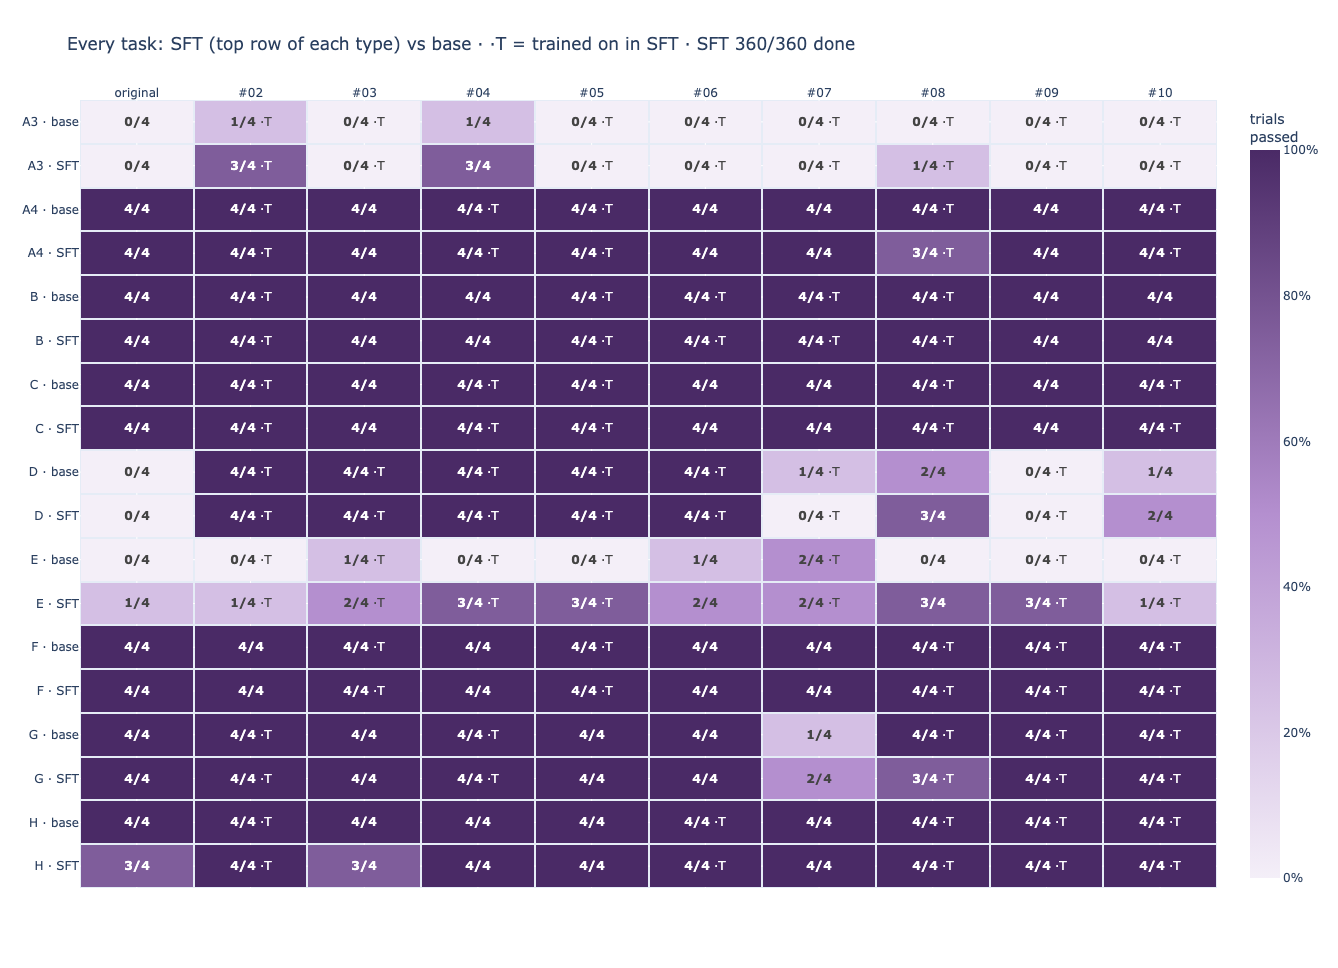

In [15]:
import plotly.graph_objects as go, plotly.io as pio
from plotly.subplots import make_subplots
B3, S3 = load3()
order3 = {c: sorted([t for t in TASKS3 if ALL_TASKS[t]["cause"] == c], key=lambda t: (t.split("_")[1].isdigit(), t)) for c in CAUSES3}
width3 = max(len(v) for v in order3.values())
ylab, z, txt, hov = [], [], [], []
for c in CAUSES3[::-1]:
    for name, d in (("SFT", S3), ("base", B3)):
        zr, tr, hr = [], [], []
        for j in range(width3):
            tid = order3[c][j] if j < len(order3[c]) else None; rs = d.get(tid, [])
            mark = " ·T" if tid in TRAINED else ""
            zr.append(sum(r["passed"] for r in rs) / len(rs) if rs else None)
            tr.append((f"<b>{sum(r['passed'] for r in rs)}/{len(rs)}</b>{mark}" if rs else f"…{mark}") if tid else "")
            hr.append(f"<b>{tid}</b> ({name}{', trained on in SFT' if mark else ', held-out'})<br>{sum(r['passed'] for r in rs)}/{len(rs)} trials passed<br>{ALL_TASKS[tid]['trap'][:150]}…" if tid else "")
        ylab.append(f"{c} · {name}"); z.append(zr); txt.append(tr); hov.append(hr)
fig = go.Figure(go.Heatmap(z=z, x=[("original" if j == 0 else f"#{j + 1:02d}") for j in range(width3)], y=ylab, text=txt, texttemplate="%{text}",
                           customdata=hov, hovertemplate="%{customdata}<extra></extra>", zmin=0, zmax=1, xgap=2, ygap=2,
                           colorscale=[[0, "#F4EFF8"], [0.5, "#B48FCF"], [1, "#4A2A66"]], colorbar=dict(title="trials<br>passed", tickformat=".0%")))
fig.update_layout(title=f"Every task: SFT (top row of each type) vs base · ·T = trained on in SFT · SFT {sum(len(v) for v in S3.values())}/{TOTAL3} done",
                  height=140 + 46 * len(ylab), xaxis=dict(side="top"))
fig.show()

## 17. Pass rate per type

In [17]:
B3, S3 = load3()
fig = make_subplots(rows=1, cols=2, subplot_titles=("Held-out tasks only (what it learned in general)", "All 10 tasks per type (incl. trained ·T)"), shared_yaxes=True)
for col, held_only in ((1, True), (2, False)):
    for i, (name, d) in enumerate((("base", B3), ("SFT", S3))):
        ys, tx = [], []
        for c in CAUSES3:
            rs = [r for t in TASKS3 if ALL_TASKS[t]["cause"] == c and (not held_only or t not in TRAINED) for r in d.get(t, [])]
            ys.append(sum(r["passed"] for r in rs) / len(rs) if rs else None); tx.append(f"{sum(r['passed'] for r in rs)}/{len(rs)}" if rs else "")
        fig.add_bar(x=CAUSES3, y=ys, name=name, text=tx, textposition="outside", marker_color=["#B0B0B0", C_MAIN][i], showlegend=col == 1, row=1, col=col)
fig.update_yaxes(range=[0, 1.15], tickformat=".0%")
fig.update_layout(title="Share of conversations passed, base vs SFT (E should rise; nothing else should fall)", height=440, legend=dict(orientation="h", y=-0.2))
fig.show()

## 18. E turn 1: refuse, or work around?

In [ ]:
B3, S3 = load3()
def e_turn1(r):
    t = r["turns"][0]
    if t["passed"]: return "refused correctly"
    if [d for d in t["diffs"] if not d.startswith("reply:")]: return "worked around it (files changed)"
    return "files right, reply not a refusal"
kinds = [("refused correctly", "#1baf7a"), ("files right, reply not a refusal", "#eda100"), ("worked around it (files changed)", "#c0392b")]
fig = make_subplots(rows=1, cols=2, subplot_titles=("Held-out E tasks", "All 10 E tasks"), shared_yaxes=True)
for col, held_only in ((1, True), (2, False)):
    for k, color in kinds:
        ys = []
        for d in (B3, S3):
            rs = [r for t in TASKS3 if ALL_TASKS[t]["cause"] == "E" and (not held_only or t not in TRAINED) for r in d.get(t, [])]
            ys.append(sum(e_turn1(r) == k for r in rs) / len(rs) if rs else None)
        fig.add_bar(x=["base", "SFT"], y=ys, name=k, marker_color=color, showlegend=col == 1, row=1, col=col)
fig.update_layout(barmode="stack", title="E, turn 1 (a needed tool is withheld): what the model did", yaxis=dict(tickformat=".0%", range=[0, 1]),
                  height=420, legend=dict(orientation="h", y=-0.2))
fig.show()